# Proyecto final · Minería de datos
## Segmentación de clientes con K-Means (*Mall Customers*)

| | |
|---|---|
| **Curso** | Minería de datos |
| **Docente** | PhD Cristian Camilo Ordoñez Quintero |
| **Integrantes** | _[Completar con los nombres del equipo]_ |
| **Dataset** | [Mall Customers – Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python) |

**Objetivo general.** Desarrollar un modelo de segmentación de clientes con el algoritmo K-Means. El modelo se evalúa con el método del codo y el coeficiente de silueta, y sus resultados se usan para analizar patrones de comportamiento y apoyar decisiones de marketing.

**Documentación del proyecto.** La documentación técnica (negocio, alcance, objetivos, plan, arquitectura y las respuestas del taller) está en `DOCUMENTACIÓN_TÉCNICA.txt`. La aplicación de despliegue está en `app.py`.

### Contenido
1. [Parte 1 – Exploración de datos](#parte1)
2. [Parte 2 – Preprocesamiento](#parte2)
3. [Parte 3 – Método del codo](#parte3)
4. [Parte 4 – Coeficiente de silueta](#parte4)
5. [Parte 5 – Modelo K-Means](#parte5)
6. [Parte 6 – Interpretación de negocio](#parte6)
7. [Parte 7 – Despliegue con Streamlit](#parte7)
8. [Conclusiones](#conclusiones)

### Metodología (conexión con el material del curso)
- **Limpieza de datos (GIGO).** Antes de modelar se verifican las dimensiones de calidad: unicidad, completitud, validez, consistencia e integridad estructural. Se aplican los procedimientos de la clase 4.1 (duplicados, nulos, rangos, normalización de texto, tipos y *outliers* con IQR/Z-score).
- **Análisis exploratorio (EDA).** Estadística descriptiva, histogramas, *boxplots*, diagramas de dispersión y correlaciones para identificar las variables clave.
- **Evaluación de modelos.** Como es un problema **no supervisado (clustering)**, se usan las métricas de agrupamiento vistas en clase: **Inercia**, **Silhouette Score** y **Davies-Bouldin**.

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import davies_bouldin_score, silhouette_samples, silhouette_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
pd.set_option("display.float_format", "{:.3f}".format)

DATA_PATH = Path("Mall_Customers.csv")
MODELS_DIR = Path("models")
OUTPUTS_DIR = Path("outputs")
RANDOM_STATE = 42
K_RANGE = range(1, 11)

<a id="parte1"></a>
# Parte 1 – Exploración de datos

## 1.1 Cargar el dataset

In [2]:
raw_customers = pd.read_csv(DATA_PATH)
print(f"Filas: {raw_customers.shape[0]} | Columnas: {raw_customers.shape[1]}")
raw_customers.head()

Filas: 200 | Columnas: 5


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
raw_customers.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB


## 1.2 Calidad de los datos y limpieza

Se aplica la lista de procedimientos de la clase de limpieza de datos. Las columnas se renombran a nombres cortos para trabajar en el código. En las gráficas se usan etiquetas en español.

In [4]:
COLUMN_NAMES = {
    "CustomerID": "customer_id",
    "Gender": "gender",
    "Age": "age",
    "Annual Income (k$)": "annual_income",
    "Spending Score (1-100)": "spending_score",
}
LABELS = {
    "customer_id": "ID cliente",
    "gender": "Género",
    "age": "Edad",
    "annual_income": "Ingreso anual (k$)",
    "spending_score": "Puntaje de gasto (1-100)",
}
NUMERIC_COLUMNS = ["age", "annual_income", "spending_score"]

customers = raw_customers.rename(columns=COLUMN_NAMES)

quality_checks = {
    "1. Filas duplicadas (unicidad)": customers.duplicated().sum(),
    "1. IDs de cliente repetidos (unicidad)": customers["customer_id"].duplicated().sum(),
    "1. Registros repetidos sin contar el ID (unicidad)": customers.drop(columns="customer_id").duplicated().sum(),
    "2. Valores nulos (completitud)": customers.isna().sum().sum(),
    "3. Edades fuera de [18, 100] (validez)": (~customers["age"].between(18, 100)).sum(),
    "3. Ingresos negativos o cero (validez)": (customers["annual_income"] <= 0).sum(),
    "3. Puntajes fuera de [1, 100] (validez)": (~customers["spending_score"].between(1, 100)).sum(),
    "5. Columnas numéricas con tipo incorrecto (integridad)": sum(
        not pd.api.types.is_numeric_dtype(customers[column]) for column in NUMERIC_COLUMNS
    ),
}
quality_report = pd.Series(quality_checks, name="Registros afectados").astype(int).to_frame()
quality_report.index.name = "Procedimiento (clase 4.1)"
quality_report

,Registros afectados
Procedimiento (clase 4.1),
1. Filas duplicadas (unicidad),0
1. IDs de cliente repetidos (unicidad),0
1. Registros repetidos sin contar el ID (unicidad),0
2. Valores nulos (completitud),0
"3. Edades fuera de [18, 100] (validez)",0
3. Ingresos negativos o cero (validez),0
"3. Puntajes fuera de [1, 100] (validez)",0
5. Columnas numéricas con tipo incorrecto (integridad),0


In [5]:
# Procedure 4 (text normalization): clean the categorical values before analysing them
customers["gender"] = customers["gender"].str.strip().str.title().astype("category")
print("Categorías de género:", list(customers["gender"].cat.categories))
customers["gender"].value_counts().rename("Clientes").to_frame()

Categorías de género: ['Female', 'Male']


,Clientes
gender,
Female,112
Male,88


**Resultado de la limpieza.** El dataset llega limpio: no tiene duplicados, nulos, valores imposibles ni tipos incorrectos, y el género solo tiene dos categorías consistentes. No hace falta eliminar ni imputar registros, así que se conservan los **200 clientes**. Los valores atípicos se analizan aparte en la sección 1.4.

## 1.3 Identificación de variables relevantes

| Variable | Tipo | Descripción | Rol en el proyecto |
|---|---|---|---|
| `CustomerID` | Identificador | Código único del cliente | **Se excluye**: no aporta información (procedimiento 15, columnas irrelevantes) |
| `Gender` | Categórica binaria | Género del cliente | Descriptiva: sirve para perfilar los clusters |
| `Age` | Numérica discreta | Edad en años | Descriptiva (se evalúa como candidata en la Parte 4) |
| `Annual Income (k$)` | Numérica | Ingreso anual en miles de dólares | **Variable de segmentación** (capacidad de compra) |
| `Spending Score (1-100)` | Numérica (índice) | Puntaje que asigna el centro comercial según el comportamiento de compra | **Variable de segmentación** (comportamiento de gasto) |

## 1.4 Análisis descriptivo básico

In [6]:
descriptive_stats = customers[NUMERIC_COLUMNS].describe().T
descriptive_stats["skewness"] = customers[NUMERIC_COLUMNS].skew()
descriptive_stats.rename(index=LABELS)

,count,mean,std,min,25%,50%,75%,max,skewness
Edad,200.000,38.850,13.969,18.000,28.750,36.000,49.000,70.000,0.486
Ingreso anual (k$),200.000,60.560,26.265,15.000,41.500,61.500,78.000,137.000,0.322
Puntaje de gasto (1-100),200.000,50.200,25.824,1.000,34.750,50.000,73.000,99.000,-0.047


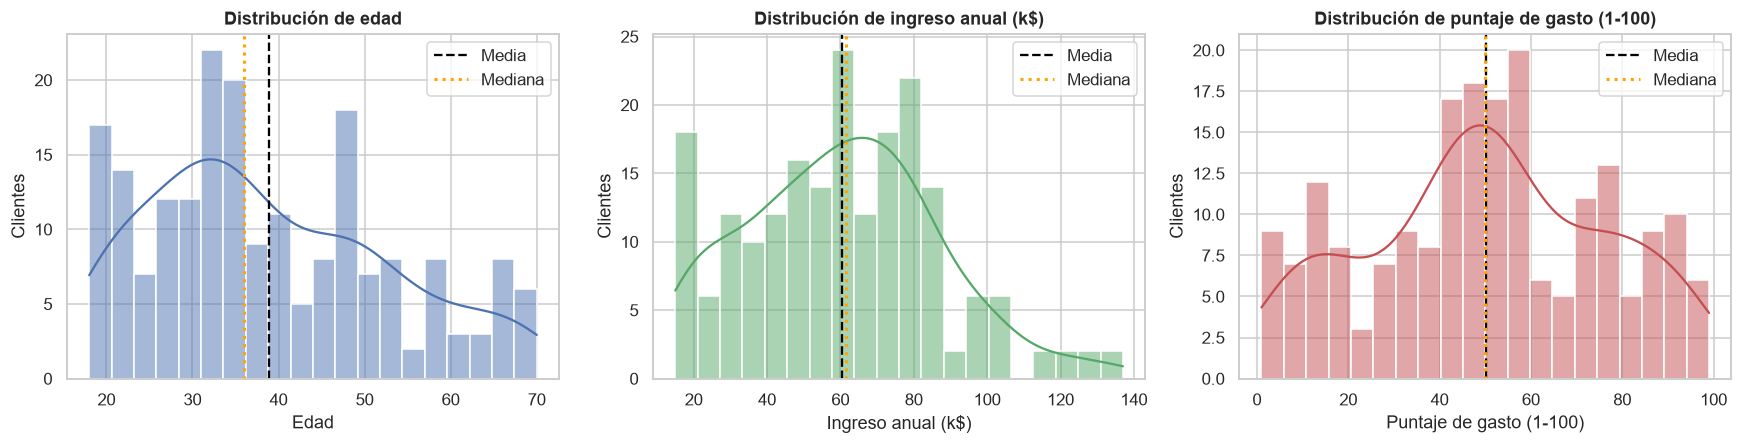

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, column, color in zip(axes, NUMERIC_COLUMNS, ["#4C72B0", "#55A868", "#C44E52"]):
    sns.histplot(customers[column], bins=20, kde=True, color=color, ax=ax)
    ax.axvline(customers[column].mean(), color="black", linestyle="--", label="Media")
    ax.axvline(customers[column].median(), color="orange", linestyle=":", linewidth=2, label="Mediana")
    ax.set(title=f"Distribución de {LABELS[column].lower()}", xlabel=LABELS[column], ylabel="Clientes")
    ax.legend()
plt.tight_layout()
plt.show()

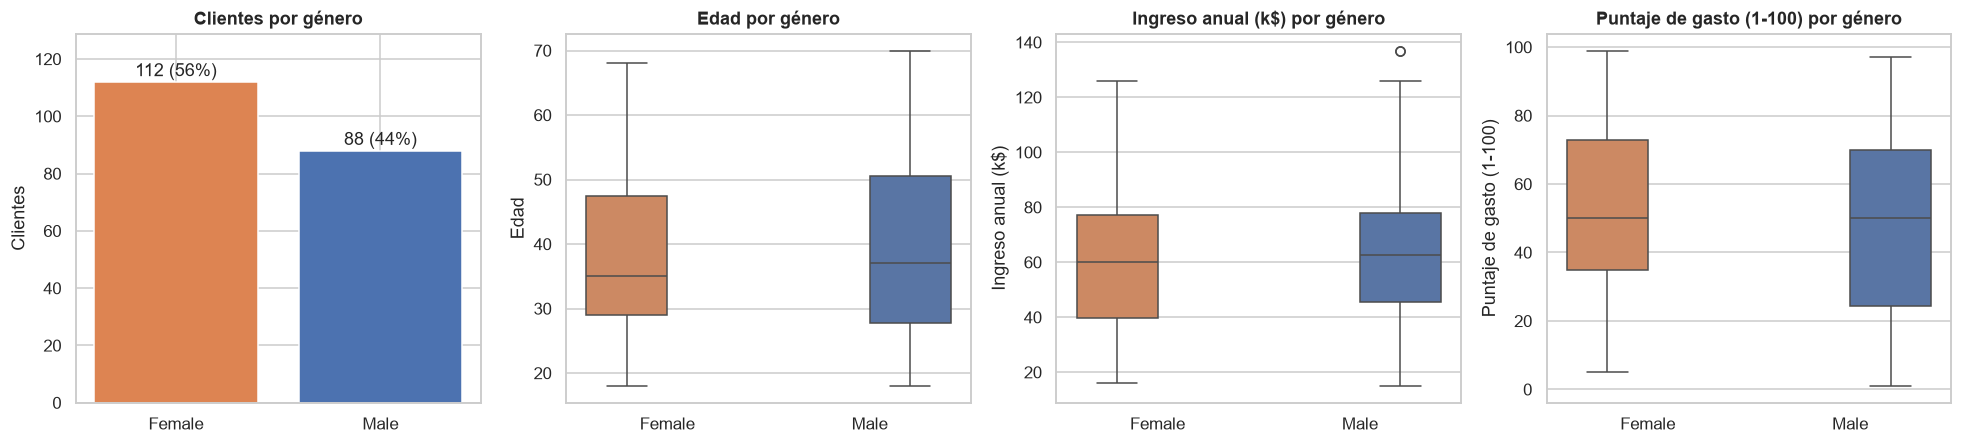

,Edad,Ingreso anual (k$),Puntaje de gasto (1-100)
gender,,,
Female,38.098,59.250,51.527
Male,39.807,62.227,48.511


In [8]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
gender_counts = customers["gender"].value_counts()
axes[0].bar(gender_counts.index, gender_counts.values, color=["#DD8452", "#4C72B0"])
for position, value in enumerate(gender_counts.values):
    axes[0].text(position, value + 2, f"{value} ({value / len(customers):.0%})", ha="center")
axes[0].set(title="Clientes por género", ylabel="Clientes", ylim=(0, gender_counts.max() * 1.15))

for ax, column in zip(axes[1:], NUMERIC_COLUMNS):
    sns.boxplot(data=customers, x="gender", y=column, hue="gender", palette=["#DD8452", "#4C72B0"], legend=False, ax=ax)
    ax.set(title=f"{LABELS[column]} por género", xlabel="", ylabel=LABELS[column])
plt.tight_layout()
plt.show()

customers.groupby("gender", observed=True)[NUMERIC_COLUMNS].mean().rename(columns=LABELS)

### Detección de valores atípicos (IQR y Z-score)
Se usan las dos técnicas del procedimiento 8 de la clase de limpieza. Un valor es atípico si queda por fuera de $[Q_1 - 1.5\,IQR,\; Q_3 + 1.5\,IQR]$ o si su $|z| > 3$.

In [9]:
def detect_outliers(series):
    first_quartile, third_quartile = series.quantile([0.25, 0.75])
    iqr = third_quartile - first_quartile
    lower_bound, upper_bound = first_quartile - 1.5 * iqr, third_quartile + 1.5 * iqr
    z_scores = (series - series.mean()) / series.std()
    iqr_outliers = series[(series < lower_bound) | (series > upper_bound)]
    return {
        "Límite inferior (IQR)": lower_bound,
        "Límite superior (IQR)": upper_bound,
        "Atípicos IQR": len(iqr_outliers),
        "Valores atípicos": sorted(iqr_outliers.unique().tolist()),
        "|z| máximo": z_scores.abs().max(),
        "Atípicos |z| > 3": int((z_scores.abs() > 3).sum()),
    }


outlier_report = pd.DataFrame({LABELS[column]: detect_outliers(customers[column]) for column in NUMERIC_COLUMNS}).T
outlier_report

,Límite inferior (IQR),Límite superior (IQR),Atípicos IQR,Valores atípicos,|z| máximo,Atípicos |z| > 3
Edad,-1.625,79.375,0,[],2.230,0
Ingreso anual (k$),-13.250,132.750,2,[137],2.910,0
Puntaje de gasto (1-100),-22.625,130.375,0,[],1.905,0


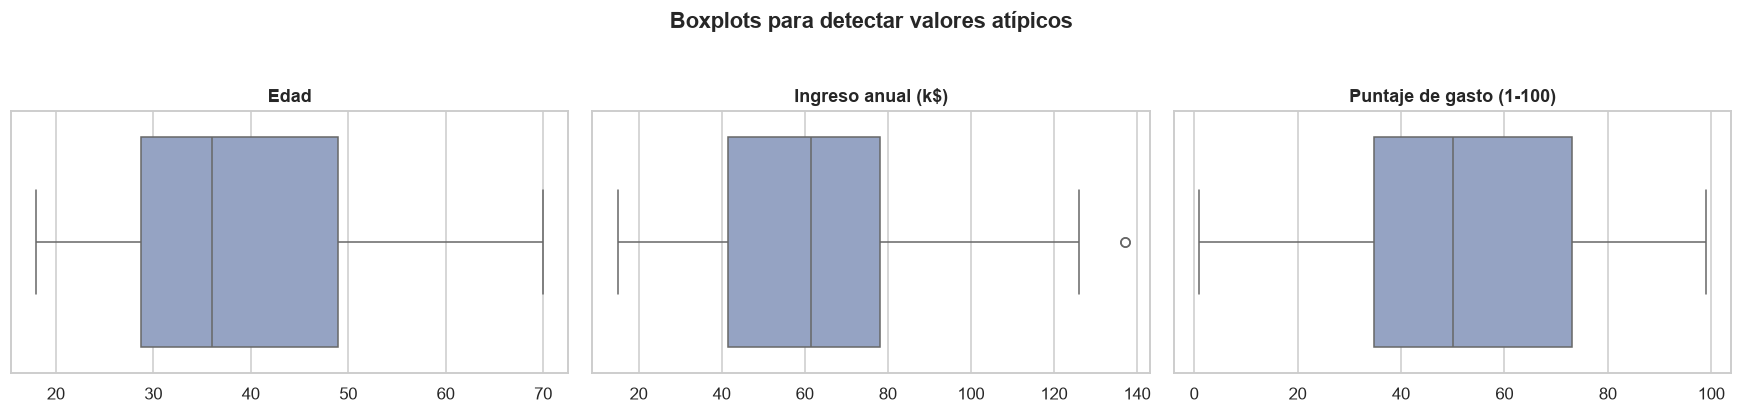

,ID cliente,Género,Edad,Ingreso anual (k$),Puntaje de gasto (1-100)
198,199,Male,32,137,18
199,200,Male,30,137,83


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.6))
for ax, column in zip(axes, NUMERIC_COLUMNS):
    sns.boxplot(x=customers[column], color="#8DA0CB", ax=ax)
    ax.set(title=LABELS[column], xlabel="")
plt.suptitle("Boxplots para detectar valores atípicos", fontweight="bold", y=1.04)
plt.tight_layout()
plt.show()

income_upper_bound = outlier_report.loc[LABELS["annual_income"], "Límite superior (IQR)"]
customers[customers["annual_income"] > income_upper_bound].rename(columns=LABELS)

### Relaciones entre variables

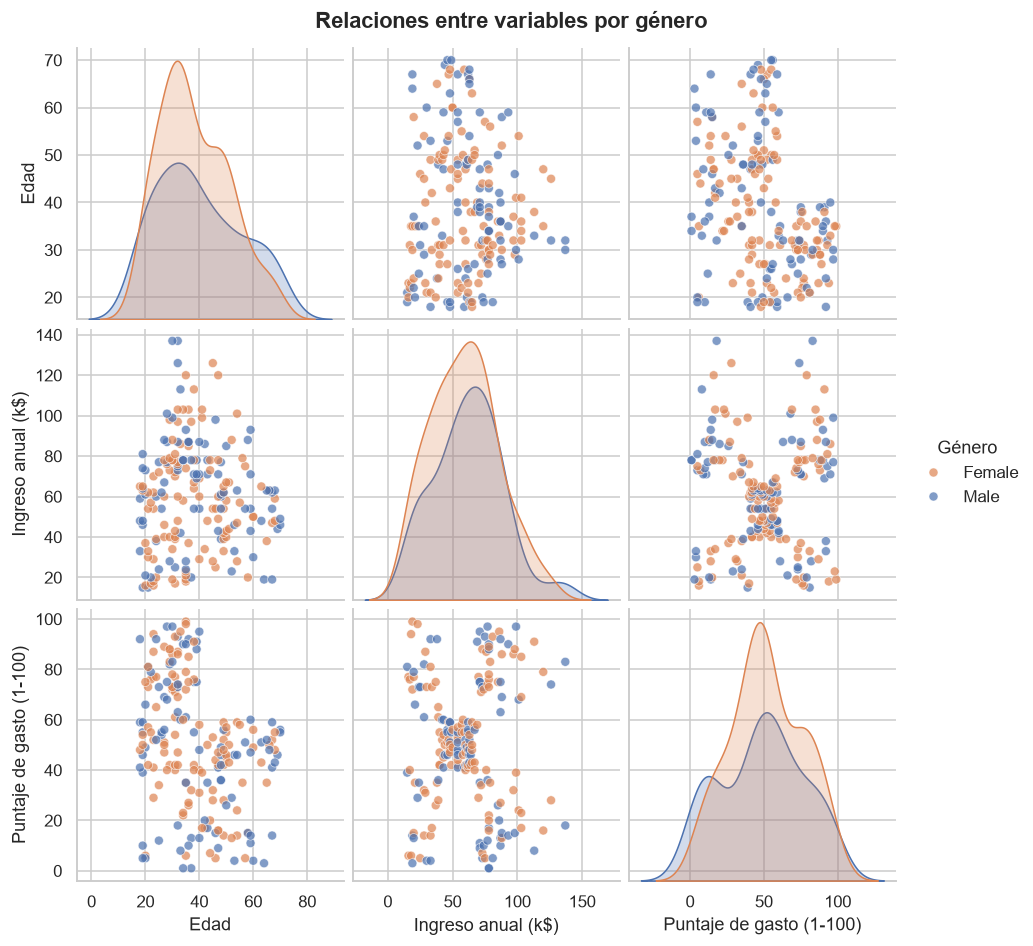

In [11]:
pair_grid = sns.pairplot(
    customers.rename(columns=LABELS),
    vars=[LABELS[column] for column in NUMERIC_COLUMNS],
    hue=LABELS["gender"],
    palette=["#DD8452", "#4C72B0"],
    diag_kind="kde",
    plot_kws={"alpha": 0.7, "s": 35},
    height=2.8,
)
pair_grid.figure.suptitle("Relaciones entre variables por género", fontweight="bold", y=1.02)
plt.show()

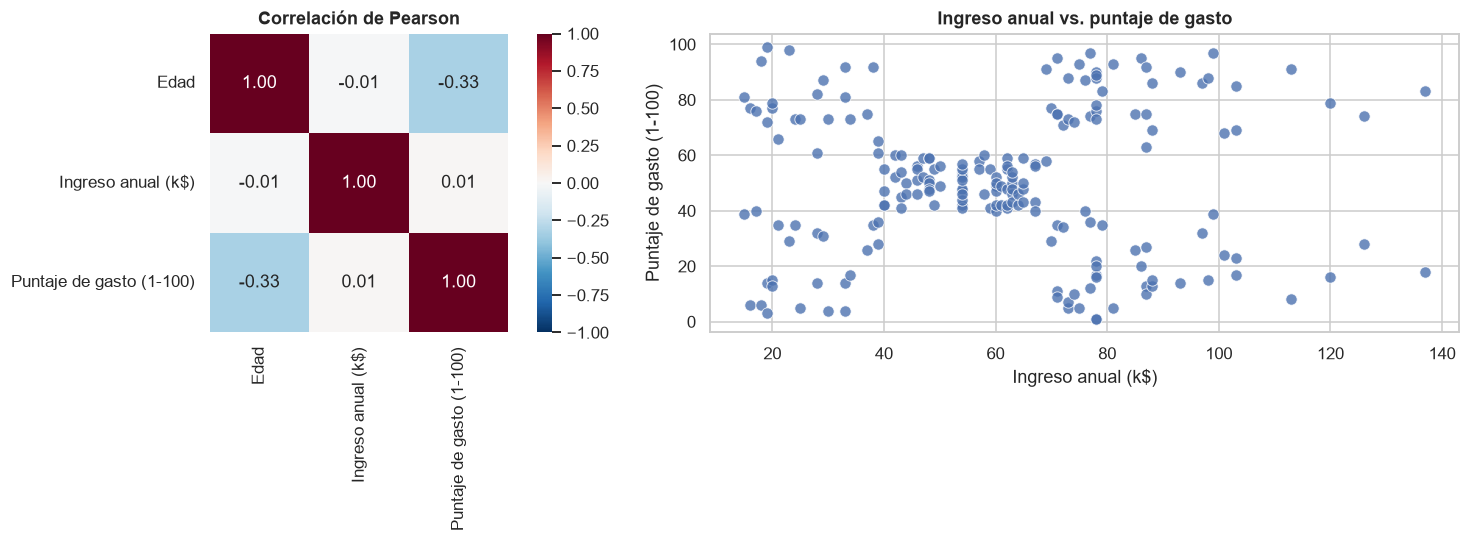

Clientes con puntaje de gasto > 60: 62
  ... de ellos con 40 años o menos: 100%
Edad máxima entre los clientes con puntaje > 60: 40 años


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 1.3]})
correlation_matrix = customers[NUMERIC_COLUMNS].corr(method="pearson").rename(index=LABELS, columns=LABELS)
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, ax=axes[0])
axes[0].set_title("Correlación de Pearson")

sns.scatterplot(data=customers, x="annual_income", y="spending_score", s=55, color="#4C72B0", alpha=0.8, ax=axes[1])
axes[1].set(
    title="Ingreso anual vs. puntaje de gasto",
    xlabel=LABELS["annual_income"],
    ylabel=LABELS["spending_score"],
)
plt.tight_layout()
plt.show()

high_spenders = customers[customers["spending_score"] > 60]
print(f"Clientes con puntaje de gasto > 60: {len(high_spenders)}")
print(f"  ... de ellos con 40 años o menos: {(high_spenders['age'] <= 40).mean():.0%}")
print(f"Edad máxima entre los clientes con puntaje > 60: {high_spenders['age'].max()} años")

### Pregunta 1.1 – ¿Qué variables son más adecuadas para segmentar clientes?

Las más adecuadas son el **ingreso anual (`Annual Income`)** y el **puntaje de gasto (`Spending Score`)**:

- **Son accionables para marketing.** Una mide la **capacidad de compra** y la otra el **comportamiento de compra** dentro del centro comercial. Combinarlas permite responder preguntas como "¿quién puede gastar más y no lo está haciendo?".
- **Aportan información independiente.** Su correlación es prácticamente nula (*r* ≈ 0.01), así que ninguna repite lo que dice la otra.
- **Muestran una estructura de grupos visible.** En el diagrama de dispersión ingreso vs. gasto se distinguen a simple vista **cinco nubes de puntos**, el escenario ideal para K-Means.

Las demás variables tienen otro rol:
- **`Age`** se usa para **describir** los segmentos, no para formarlos. En la Parte 4 se comprueba que agregarla reduce la calidad del agrupamiento (la silueta máxima baja de 0.555 a 0.428).
- **`Gender`** es binaria. K-Means usa distancia euclidiana, que no es apropiada para variables categóricas, y las diferencias entre géneros son pequeñas. Se usa solo como descriptor.
- **`CustomerID`** es un identificador y se excluye.

### Pregunta 1.2 – ¿Se identifican valores atípicos?

- **Edad y puntaje de gasto:** no tienen valores atípicos con ninguno de los dos criterios (IQR ni Z-score).
- **Ingreso anual:** el criterio IQR marca **2 clientes con 137 k$**, apenas por encima del límite superior de 132.75 k$. Su Z-score es 2.91, menor que 3, así que **no son extremos** con ese criterio.
- **Decisión: se conservan.** Son ingresos plausibles, no errores de captura (no hay valores imposibles). Además, eliminarlos quitaría justamente clientes de alto poder adquisitivo, que son relevantes para el negocio. Como las variables se estandarizan y los valores están cerca del límite, su efecto sobre los centroides es mínimo.

### Pregunta 1.3 – ¿Qué tipo de relaciones se observan entre las variables?

- **Ingreso vs. gasto.** No hay relación lineal (*r* ≈ 0.01), pero sí una **estructura no lineal en grupos**: un bloque central de ingreso y gasto medios, y cuatro grupos en las "esquinas" (ingreso alto o bajo combinado con gasto alto o bajo). Esto confirma que un buen modelo de segmentación no se puede reducir a una regresión. Los clientes se diferencian por **combinaciones** de ingreso y gasto.
- **Edad vs. gasto.** Hay una **relación negativa moderada** (*r* ≈ −0.33). Los puntajes altos (> 60) se concentran en clientes jóvenes: ninguno supera los 40 años, como muestra la celda anterior.
- **Edad vs. ingreso.** No hay relación (*r* ≈ −0.01).
- **Género.** Las distribuciones de hombres y mujeres son muy parecidas en las tres variables. Las mujeres (56 % de la muestra) tienen un puntaje de gasto medio apenas mayor (51.5 vs. 48.5).

<a id="parte2"></a>
# Parte 2 – Preprocesamiento

Se estandarizan las variables de segmentación con `StandardScaler`, que transforma cada valor con $z = \dfrac{x - \mu}{\sigma}$. Después de la transformación, cada variable tiene media 0 y desviación estándar 1.

In [13]:
FEATURES = ["annual_income", "spending_score"]

feature_matrix = customers[FEATURES]
scaler = StandardScaler()
scaled_features = scaler.fit_transform(feature_matrix)
scaled_frame = pd.DataFrame(scaled_features, columns=FEATURES)

scaling_summary = pd.DataFrame(
    {
        "Media original": feature_matrix.mean(),
        "Desv. estándar original": feature_matrix.std(ddof=0),
        "Rango original": feature_matrix.max() - feature_matrix.min(),
        "Media escalada": scaled_frame.mean(),
        "Desv. estándar escalada": scaled_frame.std(ddof=0),
    }
).rename(index=LABELS)
scaling_summary

,Media original,Desv. estándar original,Rango original,Media escalada,Desv. estándar escalada
Ingreso anual (k$),60.560,26.199,122,-0.000,1.000
Puntaje de gasto (1-100),50.200,25.759,98,-0.000,1.000


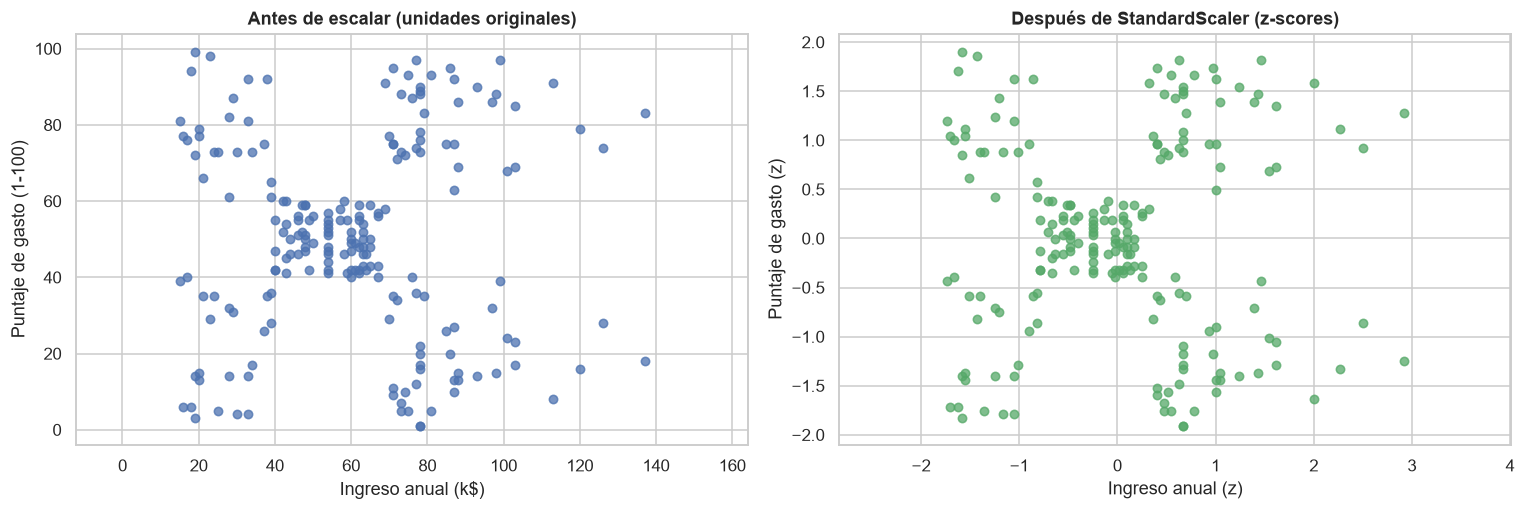

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].scatter(feature_matrix["annual_income"], feature_matrix["spending_score"], s=30, alpha=0.75, color="#4C72B0")
axes[0].set(title="Antes de escalar (unidades originales)", xlabel=LABELS["annual_income"], ylabel=LABELS["spending_score"])
axes[1].scatter(scaled_frame["annual_income"], scaled_frame["spending_score"], s=30, alpha=0.75, color="#55A868")
axes[1].set(title="Después de StandardScaler (z-scores)", xlabel="Ingreso anual (z)", ylabel="Puntaje de gasto (z)")
for ax in axes:
    ax.set_aspect("equal", adjustable="datalim")
plt.tight_layout()
plt.show()

### Pregunta 2.1 – ¿Por qué es necesario escalar las variables en el algoritmo K-Means?

K-Means asigna cada cliente al centroide más cercano según la **distancia euclidiana** $d(x, \mu) = \sqrt{\sum_j (x_j - \mu_j)^2}$. Esa distancia suma las diferencias de todas las variables en sus **unidades originales**, así que:

1. **La variable de mayor escala domina la distancia.** Si una variable se mide en pesos (millones) y otra en un puntaje de 1 a 100, la segunda prácticamente desaparece del cálculo. Los clusters se formarían solo con la primera, aunque las dos sean igual de importantes para el negocio.
2. **Las unidades son arbitrarias.** Expresar el ingreso en dólares en vez de miles de dólares no cambia la realidad del cliente, pero sin escalar cambiaría por completo la segmentación. Al estandarizar, el resultado deja de depender de la unidad de medida (procedimiento 11 de la clase, "normalización de unidades").
3. **Cada variable aporta lo mismo.** Con media 0 y desviación 1, una diferencia de "1 unidad" significa lo mismo en todas las variables: una desviación estándar. Así el ingreso y el gasto pesan igual en la segmentación.
4. **La inercia y la silueta se vuelven comparables**, porque se calculan sobre distancias en la misma escala.

En este dataset el ingreso (σ ≈ 26.2) y el puntaje (σ ≈ 25.8) ya tienen dispersiones parecidas, pero sus rangos y unidades son distintos. Además, si se agregara la edad (σ ≈ 13.9), quedaría sub-representada. Por buenas prácticas y robustez, el escalado es obligatorio. En el despliegue, el `StandardScaler` ajustado se guarda **dentro del mismo Pipeline** que el modelo, de modo que un cliente nuevo se escala exactamente igual que los datos de entrenamiento.

<a id="parte3"></a>
# Parte 3 – Método del codo

Se entrena K-Means para $K = 1, \dots, 10$ y se registra la **inercia** o WCSS (*Within-Cluster Sum of Squares*):

$$\text{Inercia} = \sum_{i=1}^{n} \lVert x_i - \mu_{c(i)} \rVert^2$$

donde $\mu_{c(i)}$ es el centroide del cluster al que pertenece el cliente $i$. En la misma pasada también se calculan la silueta y el índice de Davies-Bouldin, que se analizan en la Parte 4.

In [15]:
def evaluate_kmeans(data, k_values, random_state=RANDOM_STATE):
    rows = []
    for k in k_values:
        model = KMeans(n_clusters=k, n_init=10, random_state=random_state).fit(data)
        has_several_clusters = k > 1
        rows.append(
            {
                "k": k,
                "inertia": model.inertia_,
                "silhouette": silhouette_score(data, model.labels_) if has_several_clusters else np.nan,
                "davies_bouldin": davies_bouldin_score(data, model.labels_) if has_several_clusters else np.nan,
            }
        )
    return pd.DataFrame(rows)


def find_elbow(k_values, inertias):
    # Kneedle-style heuristic: the elbow is the point farthest from the line joining the first and last points
    k_norm = (k_values - k_values.min()) / (k_values.max() - k_values.min())
    inertia_norm = (inertias - inertias.min()) / (inertias.max() - inertias.min())
    distance_to_chord = np.abs(k_norm + inertia_norm - 1) / np.sqrt(2)
    return int(k_values[np.argmax(distance_to_chord)])


k_metrics = evaluate_kmeans(scaled_features, K_RANGE)
k_metrics["inertia_reduction_pct"] = k_metrics["inertia"].pct_change().mul(-100)

elbow_k = find_elbow(k_metrics["k"].to_numpy(), k_metrics["inertia"].to_numpy())
print(f"K sugerido por el método del codo: {elbow_k}")

k_metrics[["k", "inertia", "inertia_reduction_pct"]].rename(
    columns={"k": "K", "inertia": "Inercia (WCSS)", "inertia_reduction_pct": "Reducción vs. K-1 (%)"}
)

K sugerido por el método del codo: 5


,K,Inercia (WCSS),Reducción vs. K-1 (%)
0,1,400.000,NaN
1,2,269.691,32.577
2,3,157.704,41.524
3,4,108.921,30.933
4,5,65.568,39.802
5,6,55.057,16.031
6,7,44.865,18.513
7,8,37.228,17.021
8,9,32.392,12.990
9,10,29.982,7.441


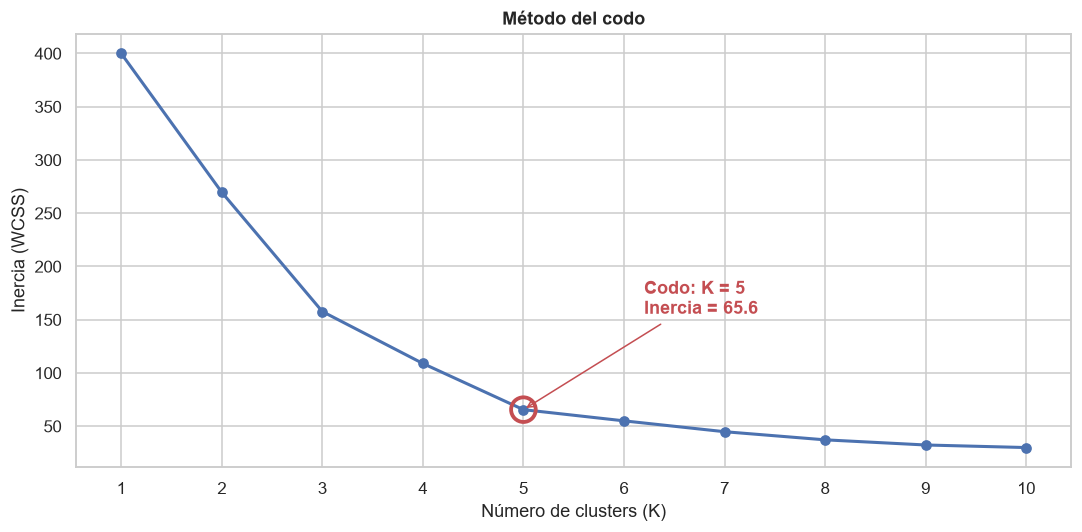

In [16]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(k_metrics["k"], k_metrics["inertia"], marker="o", linewidth=2, color="#4C72B0")
elbow_inertia = k_metrics.loc[k_metrics["k"] == elbow_k, "inertia"].item()
ax.scatter(elbow_k, elbow_inertia, s=260, facecolors="none", edgecolors="#C44E52", linewidths=2.5, zorder=3)
ax.annotate(
    f"Codo: K = {elbow_k}\nInercia = {elbow_inertia:.1f}",
    xy=(elbow_k, elbow_inertia),
    xytext=(elbow_k + 1.2, elbow_inertia + 90),
    arrowprops={"arrowstyle": "->", "color": "#C44E52"},
    color="#C44E52",
    fontweight="bold",
)
ax.set(title="Método del codo", xlabel="Número de clusters (K)", ylabel="Inercia (WCSS)", xticks=list(K_RANGE))
plt.tight_layout()
plt.show()

### Pregunta 3.1 – ¿Por qué valores cercanos a cero indican mejor ajuste?

La inercia es la **suma de las distancias al cuadrado de cada cliente a su centroide**. Si es cercana a cero, cada cliente está muy cerca del "cliente típico" de su grupo, es decir, los clusters son **compactos y homogéneos** y el centroide representa bien a sus miembros. Con inercia exactamente 0, todos los puntos coincidirían con su centroide.

**Advertencia importante.** La inercia **siempre disminuye** cuando se aumenta K, y con $K = n$ (un cluster por cliente) vale exactamente 0. Ese modelo tiene un "ajuste perfecto", pero no sirve para nada: es el equivalente al *overfitting* que vimos en la clase de evaluación de modelos, porque memoriza a cada cliente en lugar de encontrar patrones. Por eso "más cerca de cero es mejor" solo vale **para un mismo K** o como medida de compacidad. Para elegir K hay que balancear compacidad y simplicidad, y ese es el objetivo del método del codo.

### Pregunta 3.2 – ¿Cómo se identifica el punto óptimo de K?

El punto óptimo es el **"codo" de la curva**: el valor de K a partir del cual agregar un cluster más reduce poco la inercia (rendimientos decrecientes). Antes del codo, cada cluster nuevo separa grupos reales. Después, solo divide grupos que ya eran homogéneos.

En este caso:
- **Visualmente**, la curva cae con fuerza hasta **K = 5** y después se aplana.
- **Cuantitativamente**, al pasar de K = 4 a K = 5 la inercia baja un **39.8 %** (de 108.9 a 65.6). De K = 5 a K = 6 solo baja un **16.0 %**, y de ahí en adelante las reducciones se quedan entre 7 y 19 %.
- **Heurística geométrica** (punto más alejado de la recta que une K = 1 y K = 10, tipo *Kneedle*): también señala **K = 5**.

Por lo tanto, el método del codo sugiere **K = 5**.

<a id="parte4"></a>
# Parte 4 – Coeficiente de silueta

Para cada cliente $i$:

$$s(i) = \frac{b(i) - a(i)}{\max\{a(i),\, b(i)\}}$$

- $a(i)$ es la distancia promedio a los clientes de **su propio** cluster (cohesión).
- $b(i)$ es la distancia promedio a los clientes del **cluster vecino más cercano** (separación).

El coeficiente global es el promedio de $s(i)$ y va de −1 a 1. Como métrica complementaria vista en clase se reporta el índice de **Davies-Bouldin**, donde un valor más bajo es mejor.

In [17]:
silhouette_k = int(k_metrics.loc[k_metrics["silhouette"].idxmax(), "k"])
davies_bouldin_k = int(k_metrics.loc[k_metrics["davies_bouldin"].idxmin(), "k"])
print(f"K con mayor silueta: {silhouette_k} | K con menor Davies-Bouldin: {davies_bouldin_k} | K del codo: {elbow_k}")

k_metrics.loc[k_metrics["k"] >= 2, ["k", "silhouette", "davies_bouldin"]].rename(
    columns={"k": "K", "silhouette": "Coef. de silueta", "davies_bouldin": "Davies-Bouldin"}
).style.format({"Coef. de silueta": "{:.4f}", "Davies-Bouldin": "{:.4f}"}).highlight_max(
    subset="Coef. de silueta", color="#C6EFCE"
).highlight_min(subset="Davies-Bouldin", color="#C6EFCE").hide(axis="index")

K con mayor silueta: 5 | K con menor Davies-Bouldin: 5 | K del codo: 5


K,Coef. de silueta,Davies-Bouldin
2,0.3213,1.2670
3,0.4666,0.7165
4,0.4939,0.7096
5,0.5547,0.5722
6,0.5399,0.6546
7,0.5281,0.7148
8,0.4552,0.7602
9,0.4571,0.7632
10,0.4432,0.7935


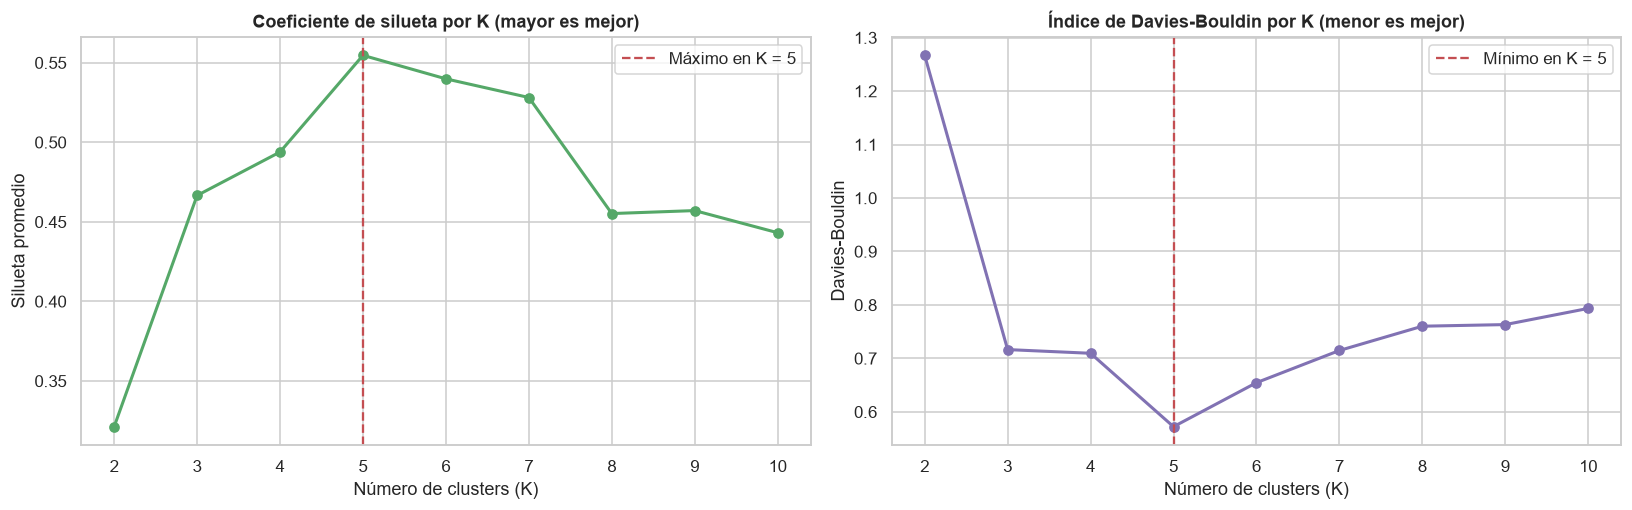

In [18]:
evaluated = k_metrics[k_metrics["k"] >= 2]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

axes[0].plot(evaluated["k"], evaluated["silhouette"], marker="o", linewidth=2, color="#55A868")
axes[0].axvline(silhouette_k, color="#C44E52", linestyle="--", label=f"Máximo en K = {silhouette_k}")
axes[0].set(title="Coeficiente de silueta por K (mayor es mejor)", xlabel="Número de clusters (K)", ylabel="Silueta promedio")
axes[0].legend()

axes[1].plot(evaluated["k"], evaluated["davies_bouldin"], marker="o", linewidth=2, color="#8172B3")
axes[1].axvline(davies_bouldin_k, color="#C44E52", linestyle="--", label=f"Mínimo en K = {davies_bouldin_k}")
axes[1].set(title="Índice de Davies-Bouldin por K (menor es mejor)", xlabel="Número de clusters (K)", ylabel="Davies-Bouldin")
axes[1].legend()
for ax in axes:
    ax.set_xticks(list(range(2, 11)))
plt.tight_layout()
plt.show()

### Diagrama de silueta para K = 5
Muestra el valor $s(i)$ de cada cliente, agrupado por cluster. Permite ver si algún grupo tiene clientes mal asignados (valores negativos) o es mucho más débil que los demás.

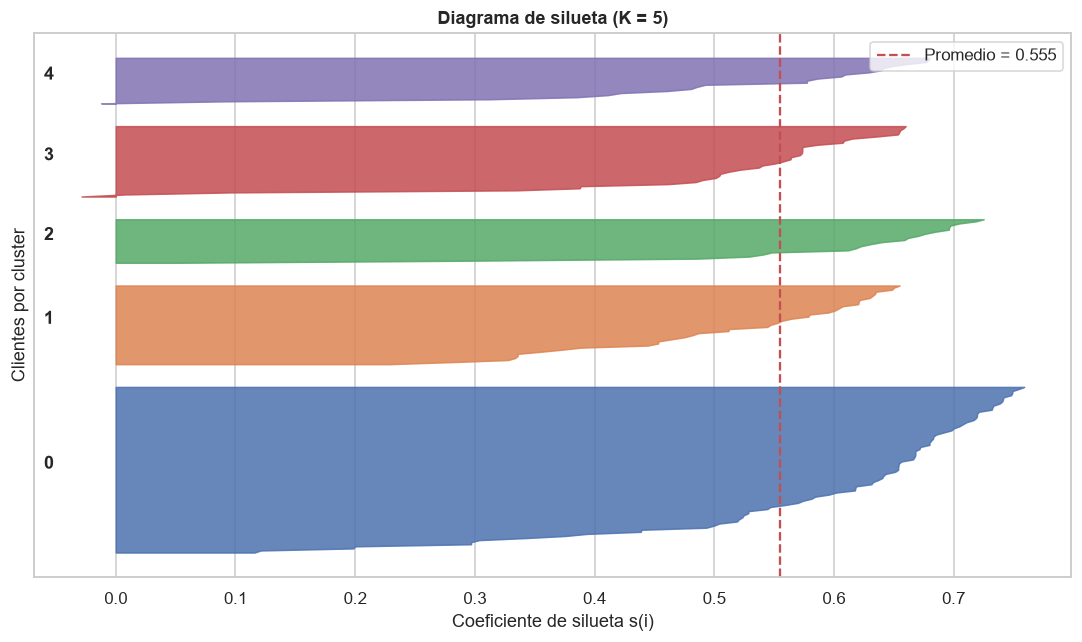

Clientes con silueta negativa: 2 de 200
Clientes con silueta < 0.25 (zona de frontera): 11


In [19]:
def plot_silhouette_diagram(data, k, ax):
    labels = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(data)
    sample_values = silhouette_samples(data, labels)
    average = sample_values.mean()
    y_lower = 10
    palette = sns.color_palette("deep", k)
    for cluster_id in range(k):
        cluster_values = np.sort(sample_values[labels == cluster_id])
        y_upper = y_lower + len(cluster_values)
        ax.fill_betweenx(np.arange(y_lower, y_upper), 0, cluster_values, color=palette[cluster_id], alpha=0.85)
        ax.text(-0.06, y_lower + len(cluster_values) / 2, str(cluster_id), fontweight="bold")
        y_lower = y_upper + 10
    ax.axvline(average, color="#C44E52", linestyle="--", label=f"Promedio = {average:.3f}")
    ax.set(title=f"Diagrama de silueta (K = {k})", xlabel="Coeficiente de silueta s(i)", ylabel="Clientes por cluster", yticks=[])
    ax.legend(loc="upper right")
    return sample_values


fig, ax = plt.subplots(figsize=(10, 6))
silhouette_values = plot_silhouette_diagram(scaled_features, silhouette_k, ax)
plt.tight_layout()
plt.show()
print(f"Clientes con silueta negativa: {(silhouette_values < 0).sum()} de {len(silhouette_values)}")
print(f"Clientes con silueta < 0.25 (zona de frontera): {(silhouette_values < 0.25).sum()}")

### Validación de la selección de variables
¿Mejora la segmentación si se agrega la edad? Se repite la evaluación con las tres variables numéricas.

In [20]:
three_feature_metrics = evaluate_kmeans(StandardScaler().fit_transform(customers[NUMERIC_COLUMNS]), range(2, 11))
best_three_features = three_feature_metrics.loc[three_feature_metrics["silhouette"].idxmax()]
best_two_features = k_metrics.loc[k_metrics["silhouette"].idxmax()]

pd.DataFrame(
    {
        "Variables": ["Ingreso + Gasto", "Edad + Ingreso + Gasto"],
        "Mejor K": [int(best_two_features["k"]), int(best_three_features["k"])],
        "Silueta máxima": [best_two_features["silhouette"], best_three_features["silhouette"]],
        "Davies-Bouldin en ese K": [best_two_features["davies_bouldin"], best_three_features["davies_bouldin"]],
    }
)

,Variables,Mejor K,Silueta máxima,Davies-Bouldin en ese K
0,Ingreso + Gasto,5,0.555,0.572
1,Edad + Ingreso + Gasto,6,0.428,0.825


### Pregunta 4.1 – ¿Qué mide el coeficiente de silueta?

Mide **qué tan bien asignado está cada cliente a su cluster** comparando dos cosas:
- **Cohesión** $a(i)$: qué tan cerca está de los miembros de su propio grupo.
- **Separación** $b(i)$: qué tan lejos está del grupo vecino más cercano.

El promedio de todos los clientes resume la calidad global del agrupamiento. A diferencia de la inercia, **no mejora automáticamente al aumentar K**, porque penaliza tanto los grupos dispersos como los grupos demasiado cercanos entre sí. Por eso sirve para elegir K.

### Pregunta 4.2 – ¿Qué significa un valor cercano a 1?

Que el cliente está **muy cerca de los miembros de su cluster y muy lejos del cluster vecino** ($a(i) \ll b(i)$), es decir, está claramente bien asignado. Si el promedio global es cercano a 1, los clusters son densos y bien separados. Como guía práctica (Kaufman & Rousseeuw): > 0.70 es una estructura fuerte, 0.51–0.70 razonable, 0.26–0.50 débil y < 0.25 sin estructura sustancial. Con **K = 5 se obtiene 0.555**, una estructura **razonable**, y es el valor más alto de todos los K evaluados.

### Pregunta 4.3 – ¿Qué implica un valor cercano a 0 o negativo?

- **Cercano a 0.** El cliente está en la **frontera** entre dos clusters ($a(i) \approx b(i)$). Daría casi lo mismo asignarlo a uno u otro, lo que indica solapamiento entre grupos.
- **Negativo.** El cliente está **más cerca de otro cluster que del suyo** ($a(i) > b(i)$). Probablemente está mal asignado. Si muchos clientes tienen silueta negativa, el K elegido no es adecuado o los datos no tienen estructura de clusters.

En el diagrama de K = 5 solo **2 de los 200 clientes** tienen silueta negativa, y apenas por debajo de cero (≈ −0.03 y ≈ −0.01). Otros 9 tienen valores menores a 0.25. Todos ellos están en la **frontera** entre el grupo central (ingreso y gasto medios) y algún grupo vecino. La mayoría (8 de 11) tiene un puntaje de gasto entre 29 y 40, justo en el límite entre gasto medio y bajo. El **94.5 %** de los clientes tiene silueta ≥ 0.25, y todos los clusters tienen una silueta promedio entre 0.50 y 0.60. Ningún grupo es débil.

### Pregunta 4.4 – ¿Coincide el valor óptimo de K con el método del codo? Justifique.

**Sí, coinciden.** Los tres criterios señalan **K = 5**:

| Criterio | K óptimo | Evidencia |
|---|---|---|
| Método del codo | 5 | La reducción de inercia cae de 39.8 % (4→5) a 16.0 % (5→6), y la heurística geométrica también marca K = 5 |
| Coeficiente de silueta | 5 | Valor máximo: 0.555 (K = 4: 0.494; K = 6: 0.540) |
| Davies-Bouldin | 5 | Valor mínimo: 0.572 |

La coincidencia tiene sentido: en el diagrama ingreso vs. gasto se ven cinco nubes naturales. Con K = 4 se fusionarían dos grupos distintos, y la silueta lo penaliza porque los clientes quedan lejos de su centroide. Con K = 6 se parte en dos un grupo que ya era homogéneo, así que la inercia apenas baja y la silueta empeora. Que métodos con lógicas diferentes (compacidad, cohesión/separación y similitud entre clusters) lleguen al mismo K hace que la elección sea **robusta**.

Además, la comparación de variables confirma la decisión de la Parte 1: con edad, ingreso y gasto la silueta máxima baja a ≈ 0.43 (K = 6). Por eso se segmenta solo con ingreso y gasto.

<a id="parte5"></a>
# Parte 5 – Modelo K-Means

### ¿Cómo funciona K-Means?
1. **Inicialización.** Se eligen K centroides iniciales. scikit-learn usa *k-means++*, que los ubica separados entre sí para converger más rápido y mejor.
2. **Asignación.** Cada cliente se asigna al centroide más cercano según la distancia euclidiana.
3. **Actualización.** Cada centroide se recalcula como el promedio de los clientes que tiene asignados.
4. **Repetición.** Los pasos 2 y 3 se repiten hasta que las asignaciones dejan de cambiar (convergencia).

El algoritmo **minimiza la inercia**. Como el resultado depende de los centroides iniciales, se ejecuta `n_init=10` veces y se conserva la solución con menor inercia. `random_state=42` hace que el resultado sea reproducible. Limitaciones: el número K se fija de antemano, el algoritmo supone grupos más o menos esféricos y de tamaño parecido, y es sensible a la escala de las variables y a los valores atípicos (por eso se estandarizó y se revisaron los atípicos).

### Entrenamiento
Se entrena el modelo final con **K = 5**. El escalador y K-Means se encapsulan en un `Pipeline`, así el mismo objeto escala y clasifica a los clientes nuevos en el despliegue.

In [21]:
OPTIMAL_K = silhouette_k
assert OPTIMAL_K == elbow_k == davies_bouldin_k, "Los criterios no coinciden: revisar la selección de K"

segmentation_pipeline = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("kmeans", KMeans(n_clusters=OPTIMAL_K, n_init=10, random_state=RANDOM_STATE)),
    ]
)
customers["cluster"] = segmentation_pipeline.fit_predict(customers[FEATURES])

fitted_scaler = segmentation_pipeline.named_steps["scaler"]
fitted_kmeans = segmentation_pipeline.named_steps["kmeans"]
final_scaled = fitted_scaler.transform(customers[FEATURES])
final_silhouette = silhouette_score(final_scaled, customers["cluster"])
final_davies_bouldin = davies_bouldin_score(final_scaled, customers["cluster"])

print(f"K = {OPTIMAL_K} | Inercia = {fitted_kmeans.inertia_:.2f} | Silueta = {final_silhouette:.4f} | Davies-Bouldin = {final_davies_bouldin:.4f}")
print(f"Iteraciones hasta converger: {fitted_kmeans.n_iter_}")
customers[["customer_id", "annual_income", "spending_score", "cluster"]].head(10).rename(columns=LABELS | {"cluster": "Cluster"})

K = 5 | Inercia = 65.57 | Silueta = 0.5547 | Davies-Bouldin = 0.5722
Iteraciones hasta converger: 4


,ID cliente,Ingreso anual (k$),Puntaje de gasto (1-100),Cluster
0,1,15,39,4
1,2,15,81,2
2,3,16,6,4
3,4,16,77,2
4,5,17,40,4
5,6,17,76,2
6,7,18,6,4
7,8,18,94,2
8,9,19,3,4
9,10,19,72,2


### Centroides

In [22]:
centroids_scaled = pd.DataFrame(fitted_kmeans.cluster_centers_, columns=[f"{column}_z" for column in FEATURES])
centroids_original = pd.DataFrame(fitted_scaler.inverse_transform(fitted_kmeans.cluster_centers_), columns=FEATURES)
centroids = pd.concat([centroids_original, centroids_scaled], axis=1)
centroids.index.name = "Cluster"
centroids.rename(
    columns={
        "annual_income": "Ingreso (k$)",
        "spending_score": "Gasto (1-100)",
        "annual_income_z": "Ingreso (z)",
        "spending_score_z": "Gasto (z)",
    }
)

,Ingreso (k$),Gasto (1-100),Ingreso (z),Gasto (z)
Cluster,,,,
0,55.296,49.519,-0.201,-0.026
1,86.538,82.128,0.992,1.240
2,25.727,79.364,-1.330,1.132
3,88.200,17.114,1.055,-1.284
4,26.304,20.913,-1.308,-1.137


In [23]:
cluster_summary = customers.groupby("cluster").agg(
    customers_count=("customer_id", "size"),
    age_mean=("age", "mean"),
    female_share=("gender", lambda gender: (gender == "Female").mean()),
    income_mean=("annual_income", "mean"),
    income_min=("annual_income", "min"),
    income_max=("annual_income", "max"),
    spending_mean=("spending_score", "mean"),
    spending_min=("spending_score", "min"),
    spending_max=("spending_score", "max"),
)
cluster_summary.insert(1, "customers_share", cluster_summary["customers_count"] / len(customers))
cluster_summary.rename(
    columns={
        "customers_count": "Clientes",
        "customers_share": "% clientes",
        "age_mean": "Edad media",
        "female_share": "% mujeres",
        "income_mean": "Ingreso medio",
        "income_min": "Ingreso mín",
        "income_max": "Ingreso máx",
        "spending_mean": "Gasto medio",
        "spending_min": "Gasto mín",
        "spending_max": "Gasto máx",
    }
).style.format(
    {"% clientes": "{:.1%}", "% mujeres": "{:.0%}", "Edad media": "{:.1f}", "Ingreso medio": "{:.1f}", "Gasto medio": "{:.1f}"}
)

,Clientes,% clientes,Edad media,% mujeres,Ingreso medio,Ingreso mín,Ingreso máx,Gasto medio,Gasto mín,Gasto máx
cluster,,,,,,,,,,
0,81,40.5%,42.7,59%,55.3,39,76,49.5,34,61
1,39,19.5%,32.7,54%,86.5,69,137,82.1,63,97
2,22,11.0%,25.3,59%,25.7,15,39,79.4,61,99
3,35,17.5%,41.1,46%,88.2,70,137,17.1,1,39
4,23,11.5%,45.2,61%,26.3,15,39,20.9,3,40


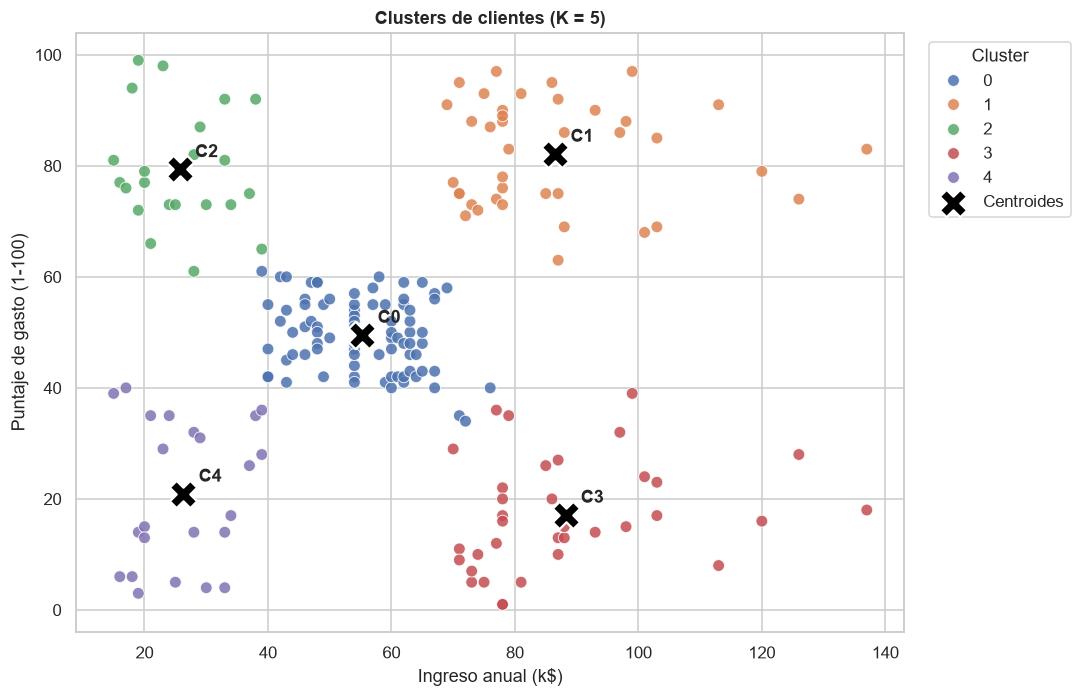

In [24]:
cluster_palette = dict(zip(range(OPTIMAL_K), sns.color_palette("deep", OPTIMAL_K)))

fig, ax = plt.subplots(figsize=(10, 6.5))
sns.scatterplot(
    data=customers, x="annual_income", y="spending_score", hue="cluster",
    palette=cluster_palette, s=60, alpha=0.85, ax=ax,
)
ax.scatter(
    centroids_original["annual_income"], centroids_original["spending_score"],
    marker="X", s=320, c="black", edgecolors="white", linewidths=1.5, label="Centroides",
)
for cluster_id, centroid in centroids_original.iterrows():
    ax.annotate(f"C{cluster_id}", (centroid["annual_income"], centroid["spending_score"]),
                xytext=(10, 8), textcoords="offset points", fontweight="bold")
ax.set(title=f"Clusters de clientes (K = {OPTIMAL_K})", xlabel=LABELS["annual_income"], ylabel=LABELS["spending_score"])
ax.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

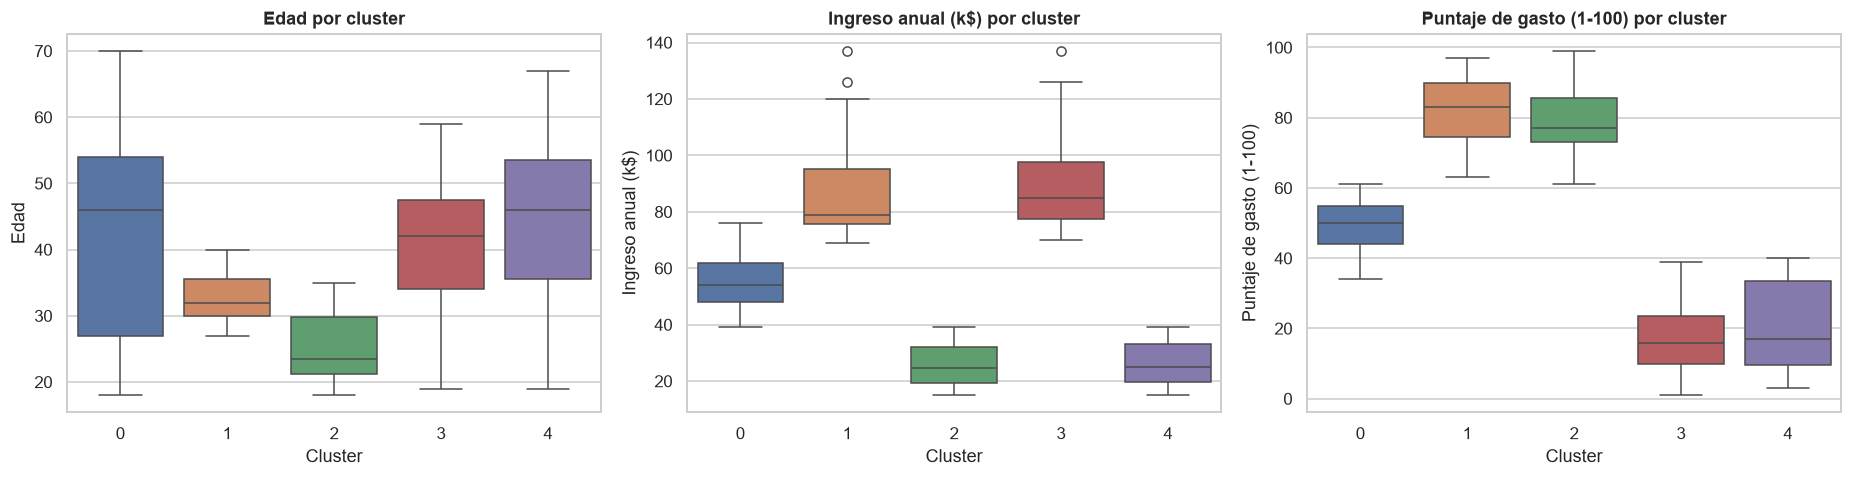

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, column in zip(axes, NUMERIC_COLUMNS):
    sns.boxplot(data=customers, x="cluster", y=column, hue="cluster", palette=cluster_palette, legend=False, ax=ax)
    ax.set(title=f"{LABELS[column]} por cluster", xlabel="Cluster", ylabel=LABELS[column])
plt.tight_layout()
plt.show()

### Pregunta 5.1 – ¿Qué representa cada cluster?

Cada cluster es un **grupo de clientes con una combinación parecida de ingreso anual y puntaje de gasto**. Su centroide es el "cliente típico" del grupo. Los números de cluster (0 a 4) son etiquetas arbitrarias de K-Means. Lo que importa es la posición del centroide:

| Centroide | Ingreso | Gasto | Qué representa |
|---|---|---|---|
| ≈ 55 k$ / 50 pts | Medio | Medio | El cliente "estándar" del centro comercial: gasta en proporción a sus ingresos |
| ≈ 87 k$ / 82 pts | Alto | Alto | Clientes con alto poder adquisitivo que efectivamente lo gastan en el centro comercial |
| ≈ 88 k$ / 17 pts | Alto | Bajo | Clientes que **pueden** gastar mucho, pero gastan poco aquí (probablemente compran en la competencia) |
| ≈ 26 k$ / 79 pts | Bajo | Alto | Clientes jóvenes que gastan por encima de lo que su ingreso sugiere (compra impulsiva o por tendencia) |
| ≈ 26 k$ / 21 pts | Bajo | Bajo | Clientes con baja capacidad y bajo gasto: compran lo necesario |

La tabla de centroides de arriba muestra qué número de cluster corresponde a cada fila.

### Pregunta 5.2 – ¿Qué diferencias existen entre los grupos obtenidos?

- **Ingreso.** Separa tres niveles bien definidos: bajo (≈ 26 k$), medio (≈ 55 k$) y alto (≈ 87 k$).
- **Gasto.** Dentro de los ingresos bajo y alto, los clientes se dividen en gastadores (≈ 80 pts) y ahorradores (≈ 17–21 pts). En el ingreso medio, el gasto se concentra alrededor de 50.
- **Edad (aunque no se usó para entrenar).** Los grupos de **gasto alto son los más jóvenes** (≈ 25 y ≈ 33 años en promedio) y los de **gasto bajo son los mayores** (≈ 41 y ≈ 45 años). El grupo medio está en ≈ 43 años. Esto coincide con la correlación negativa edad–gasto de la Parte 1.
- **Tamaño.** El grupo medio es el más grande (81 clientes, 40.5 %). Los otros cuatro tienen entre 22 y 39 clientes cada uno.
- **Género.** Predominan las mujeres en casi todos los grupos (54–61 %). La excepción es el grupo de ingreso alto y gasto bajo, con mayoría de hombres (54 %).

<a id="parte6"></a>
# Parte 6 – Interpretación de negocio

Para asignar el perfil de forma **reproducible** (sin depender del número que K-Means le da a cada cluster), se usa la posición del centroide en unidades estandarizadas. Un nivel es **alto** si $z > 0.5$, **bajo** si $z < -0.5$ y **medio** en otro caso.

| Ingreso \ Gasto | Bajo | Medio | Alto |
|---|---|---|---|
| **Alto** | Clientes con potencial | – | Clientes de alto valor |
| **Medio** | – | Clientes promedio | – |
| **Bajo** | Clientes de bajo valor | – | Compradores impulsivos |

El enunciado propone cuatro perfiles de ejemplo. Los datos muestran un quinto grupo con un comportamiento claramente distinto (ingreso bajo y gasto alto). Fusionarlo con "alto valor" escondería el riesgo de que su gasto no sea sostenible, y fusionarlo con "con potencial" mezclaría estrategias opuestas. Por eso se conserva como un perfil propio: **compradores impulsivos**.

In [26]:
PROFILE_BY_LEVELS = {
    ("high", "high"): "Clientes de alto valor",
    ("mid", "mid"): "Clientes promedio",
    ("low", "low"): "Clientes de bajo valor",
    ("high", "low"): "Clientes con potencial",
    ("low", "high"): "Compradores impulsivos",
}

PROFILES = {
    "Clientes de alto valor": {
        "description": "Ingreso alto y gasto alto. Son el núcleo rentable del centro comercial.",
        "strategy": "Programa VIP y de fidelización por niveles, acceso anticipado a colecciones, eventos exclusivos, "
                    "personal shopper y venta cruzada de marcas premium. El objetivo es retenerlos.",
        "color": "#008300",
    },
    "Clientes promedio": {
        "description": "Ingreso y gasto medios. Es el segmento más numeroso.",
        "strategy": "Programa de puntos, combos y promociones de temporada, campañas por correo y app "
                    "para aumentar la frecuencia de visita y llevar parte del segmento hacia alto valor (up-selling).",
        "color": "#2a78d6",
    },
    "Clientes de bajo valor": {
        "description": "Ingreso bajo y gasto bajo. Compran lo necesario.",
        "strategy": "Comunicación masiva de bajo costo (redes, ofertas en la app), descuentos en productos básicos, "
                    "outlet y días de precios bajos. Baja inversión de marketing por cliente.",
        "color": "#e34948",
    },
    "Clientes con potencial": {
        "description": "Ingreso alto, pero gasto bajo en el centro comercial. Tienen capacidad de compra que hoy no se captura.",
        "strategy": "Investigar por qué gastan poco (encuestas), ofertas personalizadas de alto valor, experiencias "
                    "premium, servicios de conveniencia (parqueadero preferencial, entrega a domicilio) y "
                    "beneficios de bienvenida para activar la primera compra grande.",
        "color": "#eda100",
    },
    "Compradores impulsivos": {
        "description": "Ingreso bajo, pero gasto alto. Clientes jóvenes, sensibles a tendencias y promociones.",
        "strategy": "Marketing en redes sociales e influenciadores, ventas relámpago, lanzamientos de tendencia, "
                    "descuentos para estudiantes y gamificación en la app para mantener su lealtad. "
                    "Cuidar la oferta de crédito para que su gasto sea sostenible.",
        "color": "#1baf7a",
    },
}


def level_from_z(z_value, threshold=0.5):
    if z_value > threshold:
        return "high"
    if z_value < -threshold:
        return "low"
    return "mid"


def profile_for_centroid(income_z, spending_z):
    return PROFILE_BY_LEVELS.get((level_from_z(income_z), level_from_z(spending_z)), "Clientes promedio")


cluster_profiles = {
    cluster_id: profile_for_centroid(income_z, spending_z)
    for cluster_id, (income_z, spending_z) in enumerate(fitted_kmeans.cluster_centers_)
}
assert len(set(cluster_profiles.values())) == OPTIMAL_K, "Dos clusters recibieron el mismo perfil"
customers["profile"] = customers["cluster"].map(cluster_profiles)
cluster_profiles

{0: 'Clientes promedio',
 1: 'Clientes de alto valor',
 2: 'Compradores impulsivos',
 3: 'Clientes con potencial',
 4: 'Clientes de bajo valor'}

In [27]:
profile_table = (
    customers.groupby(["cluster", "profile"])
    .agg(
        customers_count=("customer_id", "size"),
        age_mean=("age", "mean"),
        income_mean=("annual_income", "mean"),
        spending_mean=("spending_score", "mean"),
    )
    .reset_index()
    .sort_values("spending_mean", ascending=False)
)
profile_table["customers_share"] = profile_table["customers_count"] / len(customers)
profile_table["strategy"] = profile_table["profile"].map(lambda profile: PROFILES[profile]["strategy"])

profile_table.rename(
    columns={
        "cluster": "Cluster",
        "profile": "Perfil",
        "customers_count": "Clientes",
        "customers_share": "% clientes",
        "age_mean": "Edad media",
        "income_mean": "Ingreso medio (k$)",
        "spending_mean": "Gasto medio",
        "strategy": "Estrategia de marketing",
    }
)[["Cluster", "Perfil", "Clientes", "% clientes", "Edad media", "Ingreso medio (k$)", "Gasto medio", "Estrategia de marketing"]].style.format(
    {"% clientes": "{:.1%}", "Edad media": "{:.1f}", "Ingreso medio (k$)": "{:.1f}", "Gasto medio": "{:.1f}"}
).hide(axis="index").set_properties(subset=["Estrategia de marketing"], **{"text-align": "left", "white-space": "normal"})

Cluster,Perfil,Clientes,% clientes,Edad media,Ingreso medio (k$),Gasto medio,Estrategia de marketing
1,Clientes de alto valor,39,19.5%,32.7,86.5,82.1,"Programa VIP y de fidelización por niveles, acceso anticipado a colecciones, eventos exclusivos, personal shopper y venta cruzada de marcas premium. El objetivo es retenerlos."
2,Compradores impulsivos,22,11.0%,25.3,25.7,79.4,"Marketing en redes sociales e influenciadores, ventas relámpago, lanzamientos de tendencia, descuentos para estudiantes y gamificación en la app para mantener su lealtad. Cuidar la oferta de crédito para que su gasto sea sostenible."
0,Clientes promedio,81,40.5%,42.7,55.3,49.5,"Programa de puntos, combos y promociones de temporada, campañas por correo y app para aumentar la frecuencia de visita y llevar parte del segmento hacia alto valor (up-selling)."
4,Clientes de bajo valor,23,11.5%,45.2,26.3,20.9,"Comunicación masiva de bajo costo (redes, ofertas en la app), descuentos en productos básicos, outlet y días de precios bajos. Baja inversión de marketing por cliente."
3,Clientes con potencial,35,17.5%,41.1,88.2,17.1,"Investigar por qué gastan poco (encuestas), ofertas personalizadas de alto valor, experiencias premium, servicios de conveniencia (parqueadero preferencial, entrega a domicilio) y beneficios de bienvenida para activar la primera compra grande."


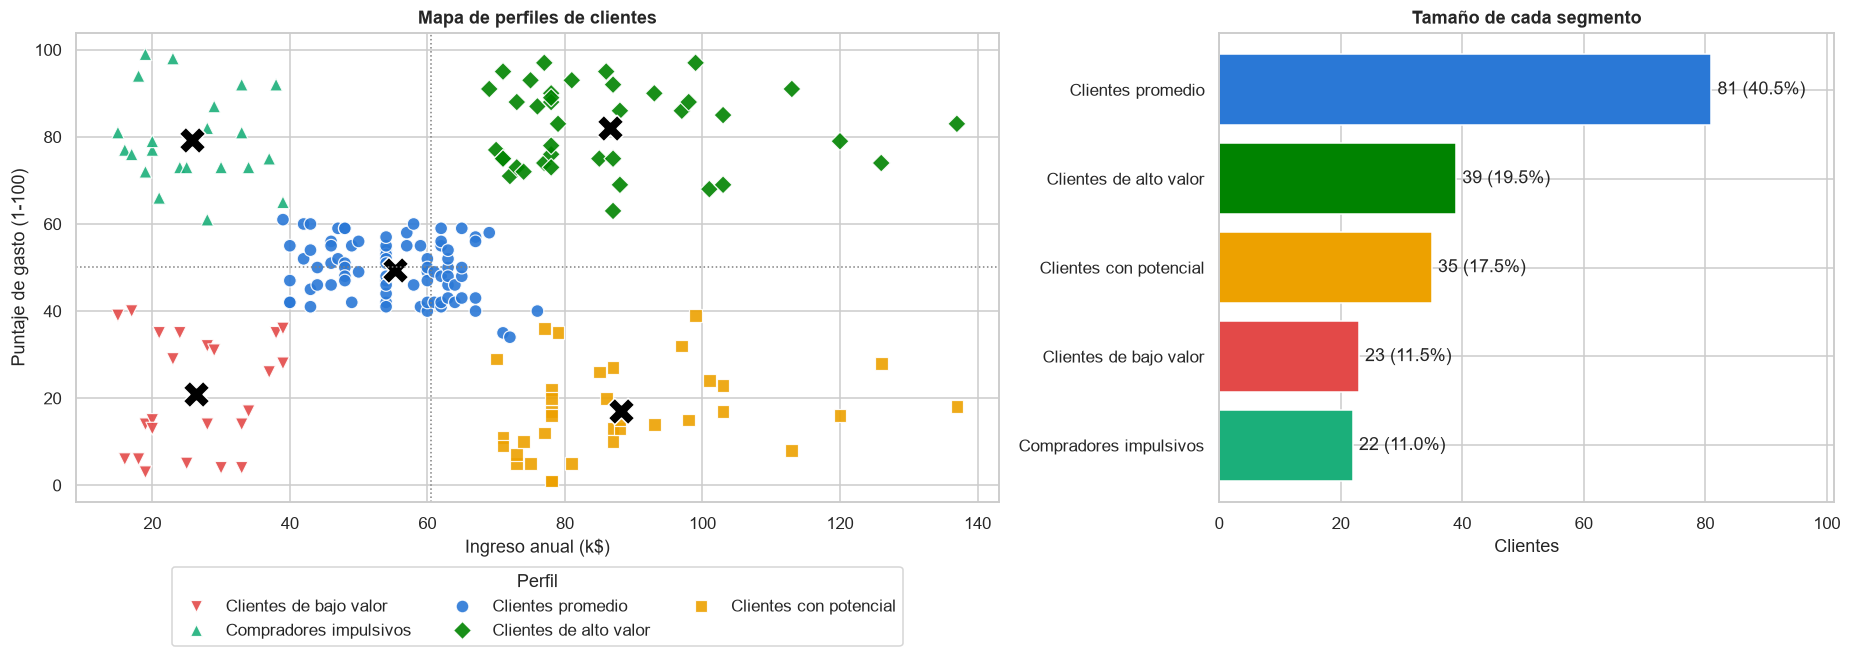

In [28]:
profile_colors = {profile: details["color"] for profile, details in PROFILES.items()}
# Marker shape is a second encoding so the profiles stay distinguishable without relying on color alone
profile_markers = dict(zip(PROFILES, ["D", "o", "v", "s", "^"]))

fig, axes = plt.subplots(1, 2, figsize=(17, 6.2), gridspec_kw={"width_ratios": [1.5, 1]})
sns.scatterplot(
    data=customers, x="annual_income", y="spending_score", hue="profile", style="profile",
    palette=profile_colors, markers=profile_markers, s=70, alpha=0.9, edgecolor="white", linewidth=0.8, ax=axes[0],
)
axes[0].scatter(centroids_original["annual_income"], centroids_original["spending_score"], marker="X", s=300, c="black", edgecolors="white")
axes[0].axvline(customers["annual_income"].mean(), color="grey", linestyle=":", linewidth=1)
axes[0].axhline(customers["spending_score"].mean(), color="grey", linestyle=":", linewidth=1)
axes[0].set(title="Mapa de perfiles de clientes", xlabel=LABELS["annual_income"], ylabel=LABELS["spending_score"])
axes[0].legend(title="Perfil", loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3)

profile_counts = customers["profile"].value_counts()
axes[1].barh(profile_counts.index, profile_counts.values, color=[profile_colors[profile] for profile in profile_counts.index])
for position, value in enumerate(profile_counts.values):
    axes[1].text(value + 1, position, f"{value} ({value / len(customers):.1%})", va="center")
axes[1].invert_yaxis()
axes[1].set(title="Tamaño de cada segmento", xlabel="Clientes", xlim=(0, profile_counts.max() * 1.25))
plt.tight_layout()
plt.show()

### Pregunta 6.1 – ¿Qué estrategias de marketing se podrían aplicar a cada grupo?

| Perfil | Quiénes son | Estrategia | Objetivo |
|---|---|---|---|
| **Clientes de alto valor** (19.5 %) | Ingreso ≈ 87 k$, gasto ≈ 82, edad ≈ 33 | Programa VIP por niveles, acceso anticipado, eventos exclusivos, personal shopper, venta cruzada premium | **Retener** y aumentar el ticket |
| **Clientes promedio** (40.5 %) | Ingreso ≈ 55 k$, gasto ≈ 50, edad ≈ 43 | Puntos de fidelización, combos y temporadas, campañas en la app y por correo | Aumentar la **frecuencia** y migrar parte del grupo a alto valor |
| **Clientes con potencial** (17.5 %) | Ingreso ≈ 88 k$, gasto ≈ 17, edad ≈ 41 | Encuestas para entender barreras, ofertas personalizadas, experiencias premium, servicios de conveniencia, beneficio de bienvenida | **Activar** su gasto: es la principal palanca de crecimiento |
| **Compradores impulsivos** (11 %) | Ingreso ≈ 26 k$, gasto ≈ 79, edad ≈ 25 | Redes sociales e influenciadores, ventas relámpago, tendencias, descuentos para estudiantes, gamificación | **Fidelizar** con una oferta de precio accesible y sostenible |
| **Clientes de bajo valor** (11.5 %) | Ingreso ≈ 26 k$, gasto ≈ 21, edad ≈ 45 | Comunicación masiva de bajo costo, descuentos en productos básicos, outlet | **Mantener** con mínima inversión |

### Pregunta 6.2 – ¿Qué segmento representa mayor oportunidad de crecimiento?

El segmento de **Clientes con potencial** (ingreso alto, gasto bajo):

- **Tienen el mismo poder adquisitivo que los clientes de alto valor** (≈ 88 k$ vs. ≈ 87 k$), pero su puntaje de gasto es **65 puntos menor** (≈ 17 vs. ≈ 82). La brecha no es de capacidad, es de **enganche con la oferta**: probablemente gastan su dinero en otros lugares.
- **Son un grupo grande** (35 clientes, 17.5 %), así que una campaña bien enfocada tiene impacto.
- **Cada cliente que se active vale mucho.** Llevarlos al nivel de gasto del grupo de alto valor es el mayor incremento posible por cliente.

Como **oportunidad secundaria** están los **Clientes promedio**: individualmente tienen menos margen de crecimiento, pero son el 40.5 % de la base, así que un aumento pequeño de su frecuencia de compra suma mucho en volumen. Los Clientes de alto valor no son una oportunidad de *crecimiento* sino de **retención**: ya gastan casi al máximo, y perderlos tendría el mayor costo.

<a id="parte7"></a>
# Parte 7 – Despliegue con Streamlit

El modelo entrenado se exporta con `joblib` junto con todo lo que necesita la aplicación: el Pipeline (escalador + K-Means), los resultados del codo y la silueta, y el mapa de clusters a perfiles y estrategias. También se exporta la lista de clientes segmentados para que el área de marketing la use directamente.

In [29]:
MODELS_DIR.mkdir(exist_ok=True)
OUTPUTS_DIR.mkdir(exist_ok=True)

model_artifact = {
    "pipeline": segmentation_pipeline,
    "features": FEATURES,
    "feature_labels": {feature: LABELS[feature] for feature in FEATURES},
    "optimal_k": OPTIMAL_K,
    "k_metrics": k_metrics.to_dict(orient="records"),
    "silhouette": final_silhouette,
    "davies_bouldin": final_davies_bouldin,
    "inertia": fitted_kmeans.inertia_,
    "cluster_profiles": cluster_profiles,
    "profiles": PROFILES,
    "random_state": RANDOM_STATE,
}
model_path = MODELS_DIR / "kmeans_segmentation.joblib"
joblib.dump(model_artifact, model_path)

segmented_path = OUTPUTS_DIR / "mall_customers_segmented.csv"
raw_customers.assign(Cluster=customers["cluster"], Perfil=customers["profile"]).to_csv(segmented_path, index=False, encoding="utf-8-sig")

print(f"Modelo guardado en:            {model_path}")
print(f"Clientes segmentados guardados: {segmented_path}")

Modelo guardado en:            models\kmeans_segmentation.joblib
Clientes segmentados guardados: outputs\mall_customers_segmented.csv


### Prueba del modelo exportado
Se carga el artefacto desde disco, como lo hará la aplicación, y se clasifican clientes nuevos.

In [30]:
loaded_artifact = joblib.load(model_path)

new_customers = pd.DataFrame(
    {
        "annual_income": [120, 20, 60, 95, 18],
        "spending_score": [92, 85, 55, 10, 8],
    }
)
new_customers["cluster"] = loaded_artifact["pipeline"].predict(new_customers[loaded_artifact["features"]])
new_customers["profile"] = new_customers["cluster"].map(loaded_artifact["cluster_profiles"])
new_customers.rename(columns=LABELS | {"cluster": "Cluster", "profile": "Perfil asignado"})

,Ingreso anual (k$),Puntaje de gasto (1-100),Cluster,Perfil asignado
0,120,92,1,Clientes de alto valor
1,20,85,2,Compradores impulsivos
2,60,55,0,Clientes promedio
3,95,10,3,Clientes con potencial
4,18,8,4,Clientes de bajo valor


### Aplicación interactiva (`app.py`)

La aplicación carga `models/kmeans_segmentation.joblib` y permite:

1. **Visualizar el método del codo**, junto con la silueta y el índice de Davies-Bouldin para cada K.
2. **Mostrar los clusters generados** en un mapa interactivo, con sus centroides y un resumen por perfil.
3. **Ingresar un nuevo cliente** (ingreso anual y puntaje de gasto).
4. **Clasificar automáticamente** al cliente en un cluster, con su perfil, la estrategia recomendada y su ubicación en el mapa.

Para ejecutarla, desde la carpeta del proyecto:

```bash
pip install -r requirements.txt
streamlit run app.py
```

> Si se modifica este cuaderno, hay que volver a ejecutarlo completo para regenerar el modelo antes de abrir la app.

<a id="conclusiones"></a>
# Conclusiones

1. **Calidad de datos.** El dataset de 200 clientes no requirió imputación ni eliminación de registros. Los dos ingresos de 137 k$ que marca el criterio IQR son valores reales y se conservaron (|z| < 3).
2. **Variables.** El ingreso anual y el puntaje de gasto son las variables adecuadas para segmentar: son independientes entre sí, accionables para el negocio y forman grupos naturales. Agregar la edad empeora la silueta (0.555 → 0.428), así que se usa solo para describir los grupos.
3. **Número de clusters.** El método del codo, el coeficiente de silueta (0.555) y el índice de Davies-Bouldin (0.572) coinciden en **K = 5**. Es una estructura de clusters razonable: solo 2 de 200 clientes tienen silueta negativa (≈ −0.03), ubicados en la frontera entre grupos.
4. **Segmentos.** Se identificaron cinco perfiles: alto valor (19.5 %), promedio (40.5 %), con potencial (17.5 %), compradores impulsivos (11 %) y bajo valor (11.5 %). Cada uno tiene una estrategia de marketing diferenciada.
5. **Oportunidad.** El segmento **con potencial** concentra la mayor oportunidad de crecimiento: tiene el mismo ingreso que el de alto valor, pero 65 puntos menos de gasto.
6. **Despliegue.** El modelo quedó empaquetado en un Pipeline reproducible y una aplicación Streamlit permite clasificar clientes nuevos en tiempo real.

**Limitaciones y trabajo futuro:** la muestra es pequeña (200 clientes) y el *spending score* es un índice, no un valor monetario. Sería útil incorporar datos transaccionales (frecuencia, recencia, ticket promedio, en un enfoque RFM), probar algoritmos como DBSCAN o clustering jerárquico, y volver a entrenar el modelo periódicamente para detectar cambios en el comportamiento de los clientes.